# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

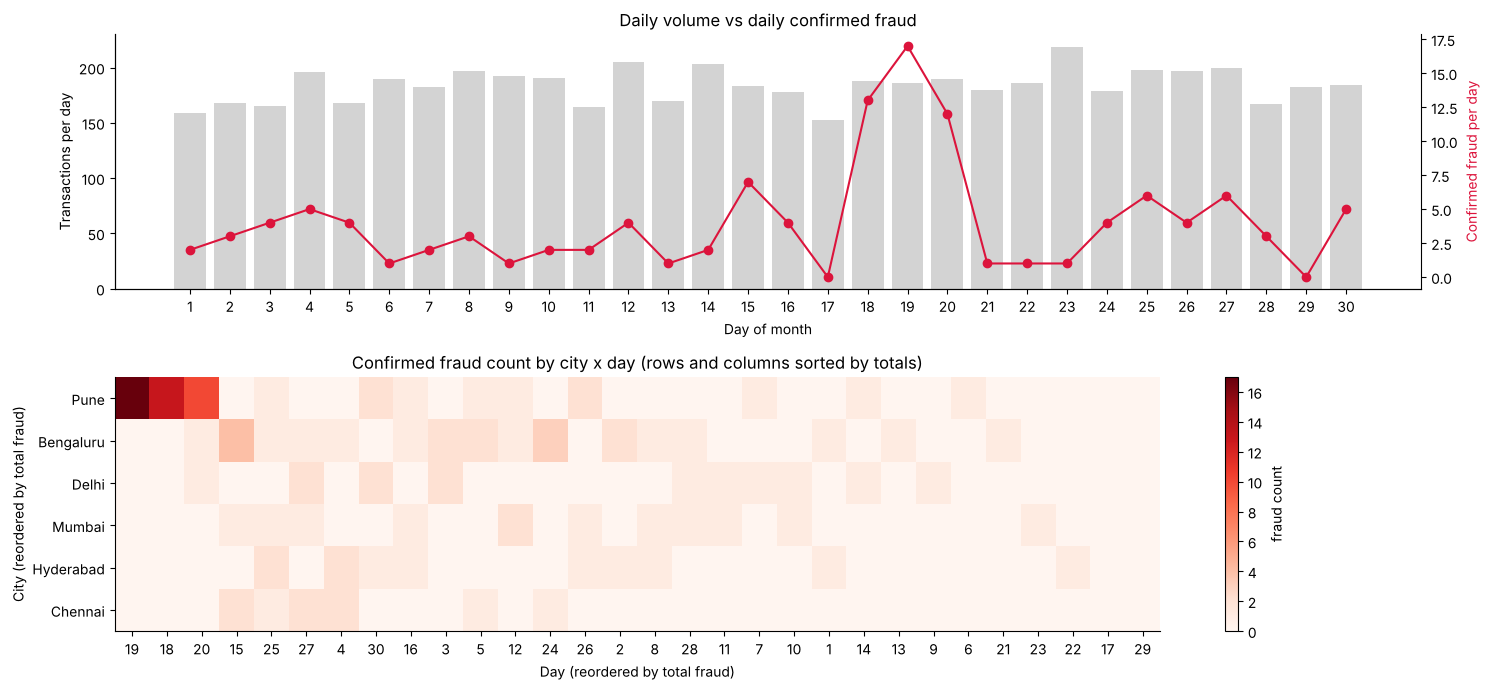

city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
           5       2


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1: daily transactions (left axis) and daily confirmed fraud (right axis)
daily = tx.groupby("day").agg(n=("txn_id", "size"), fraud=("is_fraud", "sum"))
ax = axes[0]
ax.bar(daily.index, daily.n, color="lightgrey", label="transactions")
ax.set_xlabel("Day of month"); ax.set_ylabel("Transactions per day")
ax2 = ax.twinx(); ax2.plot(daily.index, daily.fraud, "o-", color="crimson", label="confirmed fraud")
ax2.set_ylabel("Confirmed fraud per day", color="crimson"); ax2.spines["right"].set_visible(True)
ax.set_title("Daily volume vs daily confirmed fraud"); ax.set_xticks(range(1, 31))

# TODO 2: city x day matrix of confirmed-fraud counts, rows/columns reordered by their totals
heat = (tx[tx.is_fraud == 1].pivot_table(index="city", columns="day", values="txn_id", aggfunc="size", fill_value=0)
          .reindex(index=sorted(tx.city.unique()), columns=range(1, 31), fill_value=0))
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index, heat.sum(axis=0).sort_values(ascending=False).index]
im = axes[1].imshow(heat.values, aspect="auto", cmap="Reds")
axes[1].set_xticks(range(heat.shape[1])); axes[1].set_xticklabels(heat.columns)
axes[1].set_yticks(range(heat.shape[0])); axes[1].set_yticklabels(heat.index)
axes[1].set_xlabel("Day (reordered by total fraud)"); axes[1].set_ylabel("City (reordered by total fraud)")
axes[1].set_title("Confirmed fraud count by city x day (rows and columns sorted by totals)")
plt.colorbar(im, ax=axes[1], label="fraud count")

plt.tight_layout(); plt.show()

# TODO 3: hottest city-day cells
cells = tx[tx.is_fraud == 1].groupby(["city", "day"]).size().sort_values(ascending=False)
print(cells.head(6).to_string())

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

The overview showed that fraud is **not spread evenly**: total volume is flat all month (about 150-220 transactions/day), but confirmed fraud jumps on days 18-20 (13, 17 and 12 cases against a normal 1-5), and the reordered city x day matrix shows that almost all of this is **one dark block: Pune, days 18-20** (40 of the 120 frauds, 17 on day 19 alone). A list of alerts sorted by detector score shows individual transactions and would never show that they are concentrated in one city and three days. I found this by **overview first** (Shneiderman, Slide 30) and by **reordering the matrix** by row and column totals (Slide 39), which pushes the cluster to the corner where the pattern pops out.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

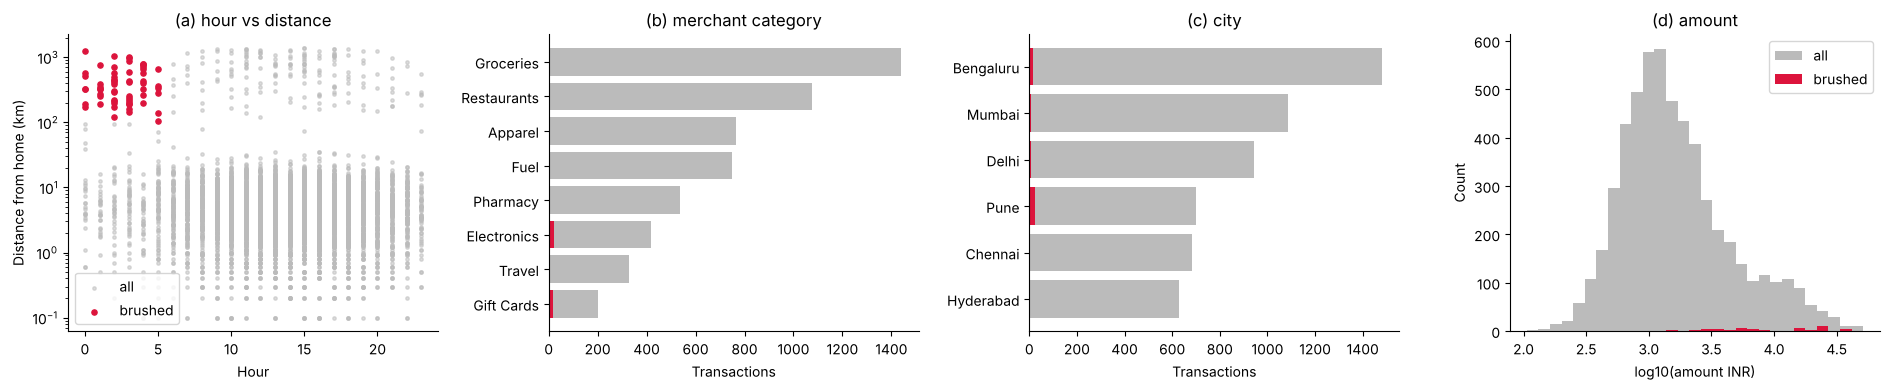

Brushed: 61 transactions | fraud rate in brush 86.9% vs overall 2.17% (40x)
Brush captures 53 of 120 frauds = 44.2% of all fraud


In [3]:
# TODO 1
brush = (tx.night) & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2
grey, red = "#bbbbbb", "crimson"
a = axes[0]
a.scatter(tx.hour[~brush], tx.distance_from_home_km[~brush], s=6, c=grey, alpha=0.5, label="all")
a.scatter(tx.hour[brush], tx.distance_from_home_km[brush], s=14, c=red, label="brushed")
a.set_yscale("log"); a.set_xlabel("Hour"); a.set_ylabel("Distance from home (km)"); a.set_title("(a) hour vs distance"); a.legend()

cats = tx.merchant_category.value_counts().index
a = axes[1]; y = np.arange(len(cats))
a.barh(y, tx.merchant_category.value_counts()[cats].values, color=grey)
a.barh(y, tx[brush].merchant_category.value_counts().reindex(cats, fill_value=0).values, color=red)
a.set_yticks(y); a.set_yticklabels(cats); a.invert_yaxis(); a.set_xlabel("Transactions"); a.set_title("(b) merchant category")

cities = tx.city.value_counts().index
a = axes[2]; y = np.arange(len(cities))
a.barh(y, tx.city.value_counts()[cities].values, color=grey)
a.barh(y, tx[brush].city.value_counts().reindex(cities, fill_value=0).values, color=red)
a.set_yticks(y); a.set_yticklabels(cities); a.invert_yaxis(); a.set_xlabel("Transactions"); a.set_title("(c) city")

bins = np.linspace(np.log10(tx.amount_inr.min()), np.log10(tx.amount_inr.max()), 30)
a = axes[3]
a.hist(np.log10(tx.amount_inr), bins=bins, color=grey, label="all")
a.hist(np.log10(tx.amount_inr[brush]), bins=bins, color=red, label="brushed")
a.set_xlabel("log10(amount INR)"); a.set_ylabel("Count"); a.set_title("(d) amount"); a.legend()

plt.tight_layout(); plt.show()

# TODO 3
fr_in, fr_all = tx.is_fraud[brush].mean(), tx.is_fraud.mean()
share = tx.is_fraud[brush].sum() / tx.is_fraud.sum()
print(f"Brushed: {brush.sum()} transactions | fraud rate in brush {fr_in:.1%} vs overall {fr_all:.2%} ({fr_in/fr_all:.0f}x)")
print(f"Brush captures {tx.is_fraud[brush].sum()} of {tx.is_fraud.sum()} frauds = {share:.1%} of all fraud")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

The rule has a high **rate** (86.9% of the 61 brushed transactions are fraud, about 40x the overall 2.2%) but a poor **capture**: it holds only 53 of the 120 frauds, i.e. **44%**, so more than half of the fraud (67 cases) occurs outside "night-time, far-from-home". Relying on this rule alone would miss most of the Pune burst, which happens mostly in the daytime (18 of the 67 missed cases are in the Pune window) and are mostly Electronics and Gift Cards. The linked views hinted at this: in the city view (c) the brushed items are concentrated in Pune (25 of 61), and the merchant-category view (b) shows the fraud concentrated in a few categories rather than evenly, so the investigators should follow these leads (city + category) and not only the rule of thumb.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1
def run():
    return big[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]
times = []
for _ in range(5):
    t0 = time.perf_counter(); run(); times.append(time.perf_counter() - t0)
best_s = min(times)

# TODO 2
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / (per_item_us * 1e-6)

# TODO 3
t_50m = per_item_us * 1e-6 * 50_000_000
skip_pct = max(0.0, (1 - 0.1 / t_50m) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 4.4 ms -> 0.0044 us/row -> max 22,960,975 rows in 0.1 s
50M rows -> 0.22 s; must skip 54.1% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

**Sampling** or, better, **aggregation (pre-computed bins / a data cube)** from the lecture's reduce techniques: for example pre-aggregate the 50M transactions into counts per hour x city x category x score-bin, and let the slider filter those few thousand cells (about 0.2 s of work on 50M rows becomes a few milliseconds). The analyst would lose the individual transactions (no per-transaction tooltips until they drill down), the slider would only work at the resolution of the bins, and with random **sampling** rare events like fraud (about 2%) could vanish from the picture.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

,threshold,alerts,TP,FP,FN,precision,recall,F1
0,0.05,2012,114,1898,6,0.057,0.950,0.107
1,0.10,1167,111,1056,9,0.095,0.925,0.172
2,0.15,786,110,676,10,0.140,0.917,0.243
3,0.20,596,106,490,14,0.178,0.883,0.296
4,0.25,471,105,366,15,0.223,0.875,0.355
5,0.30,401,104,297,16,0.259,0.867,0.399
6,0.35,355,104,251,16,0.293,0.867,0.438
7,0.40,319,104,215,16,0.326,0.867,0.474
8,0.45,283,104,179,16,0.367,0.867,0.516
9,0.50,260,101,159,19,0.388,0.842,0.532


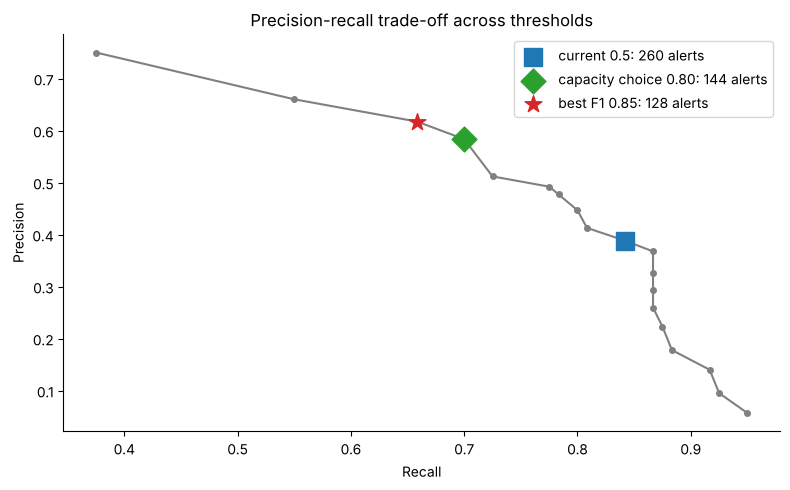

Recommendation: set threshold to 0.80 -> 144 alerts/month (<=150), precision 58%, recall 70%; current 0.50 gives 260 alerts (precision 39%, recall 84%).


In [5]:
rows = []
# TODO 1
P = int(tx.is_fraud.sum())
for t in np.round(np.arange(0.05, 0.951, 0.05), 2):
    flag = tx.detector_score >= t
    tp = int((flag & (tx.is_fraud == 1)).sum()); fp = int((flag & (tx.is_fraud == 0)).sum()); fn = P - tp
    prec = tp / (tp + fp) if tp + fp else np.nan
    rec = tp / P
    f1 = 2 * prec * rec / (prec + rec) if tp else 0.0
    rows.append(dict(threshold=t, alerts=tp + fp, TP=tp, FP=fp, FN=fn, precision=prec, recall=rec, F1=f1))

pr = pd.DataFrame(rows)
display(pr.round(3))

# TODO 2
capacity_choice = pr[pr.alerts <= 150].sort_values(["recall", "threshold"], ascending=[False, True]).iloc[0]
best_f1 = pr.loc[pr.F1.idxmax()]
current = pr[pr.threshold == 0.5].iloc[0]

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, "-o", color="0.5", ms=4)
for lab, r, col, mk in [("current 0.5", current, "tab:blue", "s"),
                        (f"capacity choice {capacity_choice.threshold:.2f}", capacity_choice, "tab:green", "D"),
                        (f"best F1 {best_f1.threshold:.2f}", best_f1, "tab:red", "*")]:
    ax.scatter(r.recall, r.precision, s=160, c=col, marker=mk, zorder=3, label=f"{lab}: {int(r.alerts)} alerts")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Precision-recall trade-off across thresholds"); ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
print(f"Recommendation: set threshold to {capacity_choice.threshold:.2f} -> {int(capacity_choice.alerts)} alerts/month "
      f"(<=150), precision {capacity_choice.precision:.0%}, recall {capacity_choice.recall:.0%}; "
      f"current 0.50 gives {int(current.alerts)} alerts (precision {current.precision:.0%}, recall {current.recall:.0%}).")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

The **Head of Fraud Ops** should make the call, with the model supplying the numbers. The capacity-constrained choice (0.80: 144 alerts, precision 58%, recall 70%) and the best-F1 choice (0.85: 128 alerts, precision 62%, recall 66%) differ by only 16 alerts and 5 caught frauds. Whether 5 more missed frauds is worth 16 fewer alerts depends on things the model cannot know: the cost of a fraud against the cost of an investigator hour, the customers' tolerance for blocked cards, and next month's staffing. F1 weighs false positives and false negatives equally, which is not a business decision. Visual analytics keeps a human in the loop (Slides 35-37) because the human has the domain knowledge and accountability, and the visualization (the precision-recall curve with the marked points) makes the trade-off visible so that they can steer the parameter.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# TODO 1
flagged = tx[tx.detector_score >= 0.3]
fig1 = px.scatter(flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
                  color_discrete_map={"confirmed fraud": "crimson", "legitimate": "steelblue"},
                  hover_data={"txn_id": True, "customer_id": True, "city": True, "merchant_category": True,
                              "distance_from_home_km": ":.0f", "detector_score": ":.3f",
                              "timestamp": False, "amount_inr": ":,", "label": False},
                  title=f"Flagged transactions (score >= 0.3): {len(flagged)} cases - drag to select, hover for details")
fig1.update_layout(dragmode="select")
fig1.show()

# TODO 2
sb = (tx.groupby(["city", "merchant_category"])
        .agg(transactions=("txn_id", "size"), fraud_rate=("is_fraud", "mean")).reset_index())
fig2 = px.sunburst(sb, path=["city", "merchant_category"], values="transactions", color="fraud_rate",
                   color_continuous_scale="Reds", title="Drill down: city -> merchant category (colour = fraud rate)")
fig2.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

A tooltip shows **one case at a time** and the viewer must hover over each of the 400 points and remember what the previous ones said, which exceeds working memory and takes minutes; nothing is visible about the whole set (how many per city, which categories, any cluster). Details-on-demand is only the *third* step of Shneiderman's mantra; it needs an overview first. The **sunburst** (city -> category, coloured by fraud rate) and the Task 1 **city x day heatmap** (or the linked brushed views of Task 2) give that overview: the investigator sees where the flagged cases concentrate and then drills down or hovers over only the interesting ones.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Window (Pune, days 18-20): 107 txns, fraud rate 37.4% | outside: 1.48% | chi2=619.3, p=1.06e-136
Pune days 18-20 (window)     n=  107  fraud= 40  rate=37.38%
Pune other days              n=  593  fraud= 11  rate=1.85%
Other cities days 18-20      n=  457  fraud=  2  rate=0.44%
Rest                         n= 4363  fraud= 67  rate=1.54%


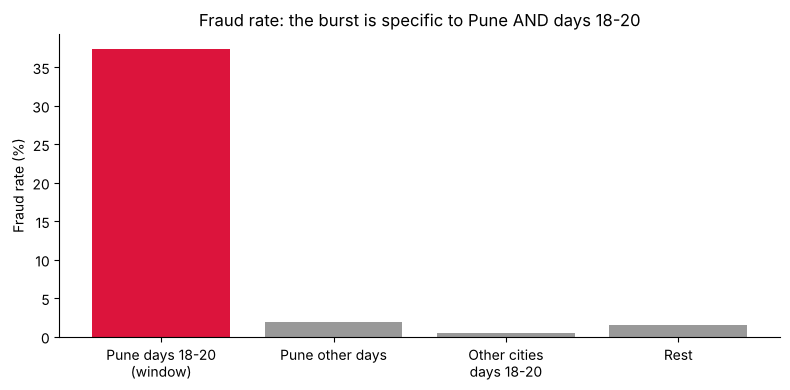

Verdict: SUPPORTED - a localized burst (one city, three days); the data cannot show that one organised ring is behind it.


In [7]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask -- "a fraud burst in Pune on days 18-20"
in_window = (tx.city == "Pune") & tx.day.between(18, 20)

# TODO 2
ct = pd.crosstab(in_window, tx.is_fraud)
chi2, p, dof, _ = chi2_contingency(ct)
r_in, r_out = tx.is_fraud[in_window].mean(), tx.is_fraud[~in_window].mean()
print(f"Window (Pune, days 18-20): {in_window.sum()} txns, fraud rate {r_in:.1%} | outside: {r_out:.2%} | chi2={chi2:.1f}, p={p:.2e}")

# TODO 3: counter-example searches
same_city_other_days = (tx.city == "Pune") & ~tx.day.between(18, 20)
other_cities_same_days = (tx.city != "Pune") & tx.day.between(18, 20)
rest = (tx.city != "Pune") & ~tx.day.between(18, 20)
groups = {"Pune days 18-20\n(window)": in_window, "Pune other days": same_city_other_days,
          "Other cities\ndays 18-20": other_cities_same_days, "Rest": rest}
rates = {k: tx.is_fraud[m].mean() for k, m in groups.items()}
for k, m in groups.items():
    print(f"{k.replace(chr(10), ' '):28s} n={int(m.sum()):5d}  fraud={int(tx.is_fraud[m].sum()):3d}  rate={rates[k]:.2%}")

# TODO 4
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(list(rates), [v * 100 for v in rates.values()], color=["crimson", "0.6", "0.6", "0.6"])
ax.set_ylabel("Fraud rate (%)"); ax.set_title("Fraud rate: the burst is specific to Pune AND days 18-20")
plt.tight_layout(); plt.show()

# TODO 5
print("Verdict:", "SUPPORTED" if (p < 0.001 and rates[list(rates)[0]] > 3 * max(list(rates.values())[1:])) else "NOT SUPPORTED",
      "- a localized burst (one city, three days); the data cannot show that one organised ring is behind it.")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

The search that could most clearly have killed it is **(b) other cities on the same days**. If Fraud had risen in all cities on days 18-20 (instead of 0.44%, only 2 cases), the cause would be time-based and system-wide (a data breach or merchant compromise affecting everyone, a processor or detector problem, or a holiday/sale spike) and not something about Pune. Search **(a) Pune on other days** would also have killed the "burst" idea if Pune had been high all month (1.85% compared with 1.54% elsewhere); that would suggest a standing local weakness, such as a compromised terminal or merchant in Pune, rather than a three-day event. Both came out low, so the hypothesis survived: the problem is specific to Pune *and* to those three days.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

**Final note:**

Last month there were 120 confirmed frauds among 5,520 transactions (2.2%), and 40 of them occurred in a single burst in **Pune on days 18-20** (a 37% fraud rate against 1.5% elsewhere, chi-square p about 1e-136), while the other cities on those days were normal (0.4%). I recommend raising the detector threshold from 0.5 (260 alerts, 110 more than the team can review) to **0.80**, which gives 144 alerts (within the 150 capacity) with 58% precision and 70% recall (84 of the 120 frauds); the best-F1 value of 0.85 only gains 0.001 in F1 and misses 5 more frauds, so this is a trade-off for you, the human in the loop, to decide. The first interactive view to build is the **city x day overview with linked brushing** (overview first, then filter and details on demand), because that is how the Pune burst was found within seconds; on 50M rows a slider would need about 0.2 s, so it must run on pre-aggregated data to stay within the 0.1 s budget. The Pune data suggest a localised burst, but they cannot show an organised ring, which needs an investigation of the customers, merchants and devices involved. Finally, add the **feedback loop (Slide 51)**: investigators' confirmed labels, including the 67 frauds the night/far-from-home rule missed, should be fed back to retrain and re-tune the detector so that next month's scores are better.